# Proyecto final · 01 Entrenamiento
## ¿Dónde aparece red vial nueva? Tipología y modelo por celdas

**Insumos:** dos geopaquetes de ejes viales por ciudad (versión antigua, base 2014, y versión actual, CPV2021; INEC), en `datos/`.

**Pregunta.** Dada la red vial de 2014, ¿en qué celdas de 250 m aparece red nueva en 2021?

**Qué cambia frente al notebook anterior**

| Antes | Ahora | Motivo |
|---|---|---|
| Unidad = área amanzanada (763 filas, de Guayaquil a caseríos) | Unidad = celda de 250 m | Unidades comparables y muchas más observaciones |
| Red nueva = ejes fuera de la delimitación 2014 | Red nueva = ejes 2021 a más de 30 m de la red 2014 | Mide la red, no el polígono; era el primer punto de "trabajo futuro" |
| Regresión de `pct_expansion` (35 % de ceros) | Clasificación: la celda recibe red nueva o no | Resuelve el exceso de ceros |
| Validación cruzada aleatoria | Validación cruzada **espacial** por bloques de 2 km | Las celdas vecinas se parecen; la partición aleatoria infla las métricas |
| Nada se guarda | `modelo/paquete.joblib` | Sin un modelo serializado no hay despliegue |
| Funciones dentro del notebook | `urbano.py`, que también importa la app | La app calcula las variables con el mismo código del entrenamiento |

**Flujo:** insumos (2) → tabla de celdas (3) → tipología por clusters (4) → modelos (5) → modelo final (6) → exportación (7).

In [1]:
#!pip install -r requirements.txt
import json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, pyogrio

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (silhouette_score, roc_auc_score, average_precision_score,
                             brier_score_loss, precision_score, recall_score)

import urbano as u

### 1. Parámetros
Los parámetros geométricos (tamaño de celda, radio del universo, distancia y longitud que definen la red nueva) están en `urbano.py`, porque la app debe usar los mismos valores.

In [2]:
DATOS    = Path("datos")
CIUDADES = ["ibarra"]         # ciudades de entrenamiento: datos/ejes_antigua_<ciudad>.gpkg y datos/ejes_actual_<ciudad>.gpkg
ANIOS    = {"antigua": 2014, "actual": 2021}

N_TIPOS   = 4                 # grupos de la tipología (ver 4.1)
NOMBRES_4 = ["Núcleo consolidado", "Borde urbano", "Periferia inmediata", "Entorno disperso"]   # de más a menos densidad de vecindad

TAM_BLOQUE = 2000             # m; bloques de la validación cruzada espacial
N_PLIEGUES = 5
N_ARBOLES  = 300
MIN_HOJA   = 10               # celdas mínimas por hoja: limita el sobreajuste
SEMILLA    = 42

RUTA_PAQUETE = Path("modelo/paquete.joblib")

# Paleta: un color fijo por tipo (en orden) y un solo tono para magnitudes
COLOR_TIPO = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
AZUL, GRIS, TINTA = "#2a78d6", "#c3c2b7", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
                     "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
                     "axes.titlesize": 10, "axes.titlelocation": "left", "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb"})

print("Parámetros de urbano.py:", {k: getattr(u, k) for k in ["CRS_TRABAJO", "TAM_CELDA", "RADIO_UNIVERSO", "DIST_NUEVA", "MIN_NUEVA_M", "DENS_NUCLEO"]})

Parámetros de urbano.py: {'CRS_TRABAJO': 'EPSG:31992', 'TAM_CELDA': 250, 'RADIO_UNIVERSO': 500, 'DIST_NUEVA': 30, 'MIN_NUEVA_M': 50, 'DENS_NUCLEO': 8.0}


### 2. Insumos
Inventario de los geopaquetes sin cargar las geometrías. Las características que deben cumplir están en el `README.md`.

In [3]:
inv = []
for ciudad in CIUDADES:
    for version in ANIOS:
        ruta = DATOS / f"ejes_{version}_{ciudad}.gpkg"
        i = pyogrio.read_info(ruta)
        inv.append({"ciudad": ciudad, "versión": version, "año": ANIOS[version], "entidades": i["features"],
                    "geometría": i["geometry_type"], "CRS": i["crs"], "MB": round(ruta.stat().st_size / 1e6, 1)})
pd.DataFrame(inv).set_index(["ciudad", "versión"])

año  entidades        geometría         CRS   MB
ciudad versión                                                   
ibarra antigua  2014       6307  MultiLineString  EPSG:31992  2.0
       actual   2021       9883  MultiLineString  EPSG:31992  3.3

### 3. Tabla de celdas
`urbano.tabla_celdas` hace, por ciudad:

1. **Segmentos.** `line_merge` y separación de multipartes; longitud, punto medio y orientación axial (cos 2θ, sin 2θ) de cada segmento.
2. **Malla** de 250 m. Solo entran las celdas a 500 m o menos de la red 2014: es el **universo** del modelo y se define sin mirar 2021.
3. **Variables 2014** de cada celda y de su vecindad (tabla siguiente).
4. **Objetivo.** Un segmento 2021 es nuevo si su punto medio está a más de 30 m de la red 2014. `crece` = 1 si la celda suma al menos 50 m de red nueva.

In [4]:
tablas, resumen = [], {}
for ciudad in CIUDADES:
    c, info = u.tabla_celdas(DATOS / f"ejes_antigua_{ciudad}.gpkg", DATOS / f"ejes_actual_{ciudad}.gpkg")
    tablas.append(c.assign(ciudad=ciudad))
    resumen[ciudad] = {**info, "celdas": len(c), "celdas con red nueva": int(c.crece.sum()),
                       "% celdas con red nueva": 100 * c.crece.mean(),
                       "% de la red nueva dentro del universo": 100 * info["km_nuevos_en_universo"] / info["km_nuevos"]}
celdas = pd.concat(tablas, ignore_index=True)
display(pd.DataFrame(resumen).round(1))
display(pd.DataFrame({"descripción": u.DESCRIPCION}).join(celdas[u.VARIABLES].describe().T[["mean", "50%", "max"]].round(2)))

,ibarra
segmentos_ant,6307.0
km_ant,662.2
segmentos_act,9885.0
km_act,812.9
km_nuevos,118.3
km_nuevos_en_universo,110.2
celdas,1564.0
celdas con red nueva,360.0
% celdas con red nueva,23.0
% de la red nueva dentro del universo,93.2


,descripción,mean,50%,max
dens,Densidad vial de la celda (km/km²),6.77,0.00,42.22
dens_v1,Densidad media en la vecindad 3×3 (km/km²),6.77,4.79,27.01
dens_v2,Densidad media en la vecindad 5×5 (km/km²),6.66,4.42,24.75
dens_v4,Densidad media en la vecindad 9×9 (km/km²),6.08,4.56,20.37
frac_v1,Fracción de las 8 celdas vecinas que tienen red,0.50,0.50,1.00
coher_v2,Coherencia de orientación en la vecindad 5×5 (...,0.19,0.16,1.00
dist_red,Distancia a la celda con red más cercana (m),169.35,250.00,500.00
dist_nucleo,Distancia al núcleo consolidado más cercano (m),5709.38,500.00,65525.28


### 4. Tipología de celdas (clusters)
KMeans sobre seis variables de 2014 estandarizadas (las de densidad y distancia, en logaritmo). La tipología describe **en qué tipo de tejido** está cada celda; en la sección 5 se prueba si además sirve para modelar.

#### 4.1. Número de grupos

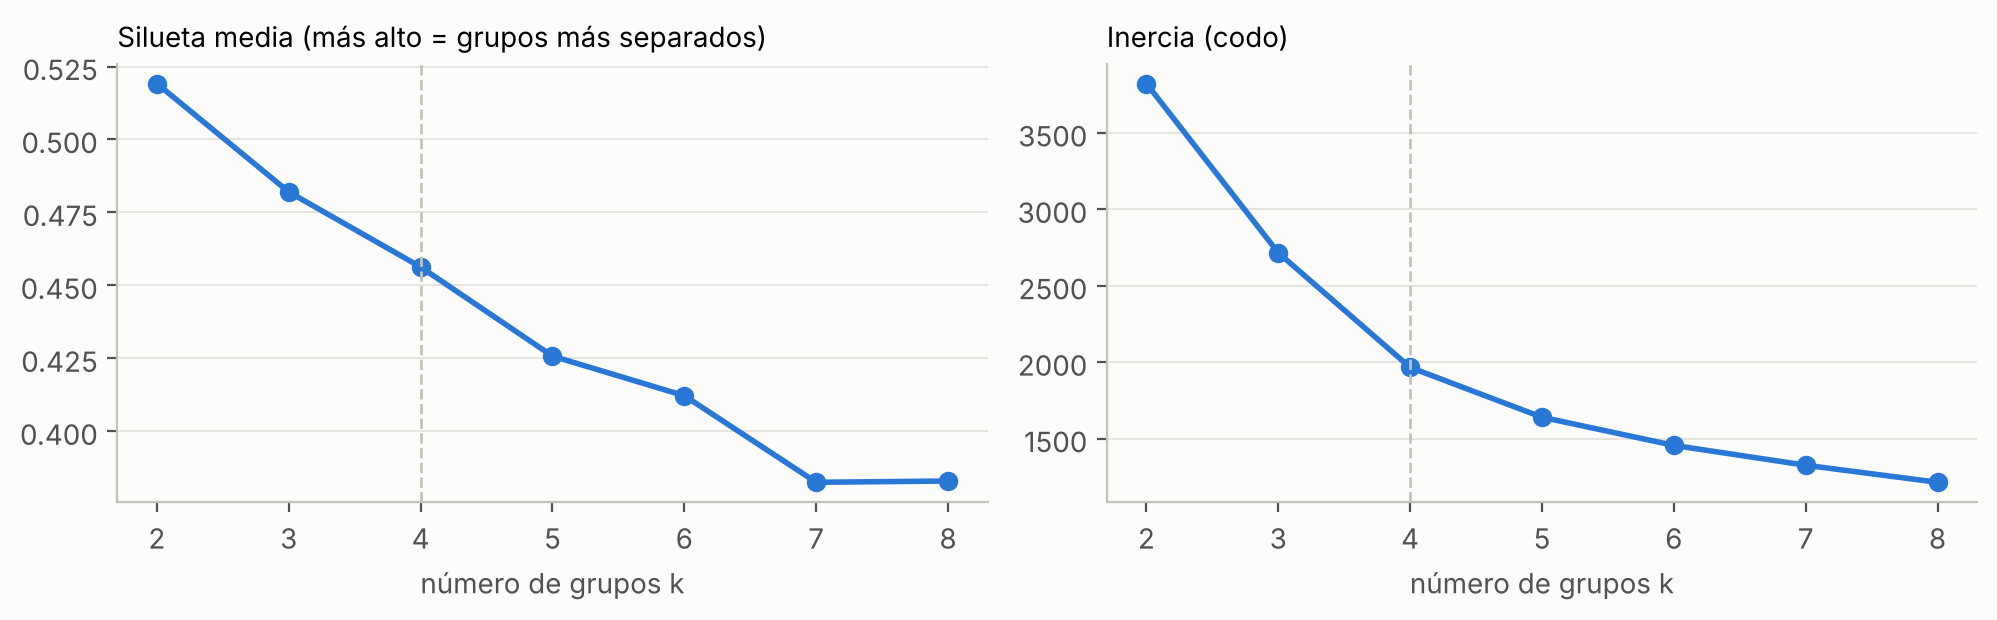

k,2,3,4,5,6,7,8
silueta,0.519,0.482,0.456,0.426,0.412,0.383,0.383
inercia,3822.896,2716.009,1965.864,1639.668,1455.482,1325.508,1213.978


In [5]:
Z = StandardScaler().fit_transform(u.matriz_cluster(celdas))
sil = pd.DataFrame([{"k": k, "silueta": silhouette_score(Z, (km := KMeans(k, n_init=10, random_state=SEMILLA).fit(Z)).labels_),
                     "inercia": km.inertia_} for k in range(2, 9)]).set_index("k")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, titulo in zip(axs, ["silueta", "inercia"], ["Silueta media (más alto = grupos más separados)", "Inercia (codo)"]):
    ax.plot(sil.index, sil[col], color=AZUL, linewidth=2, marker="o", markersize=6)
    ax.axvline(N_TIPOS, color=GRIS, linewidth=1, linestyle="--")
    ax.set(title=titulo, xlabel="número de grupos k"); ax.grid(axis="y", color="#e1e0d9", linewidth=0.6)
plt.tight_layout(); plt.show()
sil.round(3).T

La silueta es máxima en k = 2 y baja de forma continua: los datos no forman grupos naturales separados, son un **gradiente** del centro a la periferia. Con k = 2 la partición solo distingue "celda con red" de "celda sin red". Se usa **k = 4** porque es el corte más fino que todavía se interpreta, sabiendo que es una partición de un continuo y no cuatro clases discretas.

#### 4.2. Ajuste y perfil de los tipos
Los grupos se renumeran de mayor a menor densidad de vecindad para que el número del tipo sea estable entre ejecuciones.

In [6]:
tipologia = make_pipeline(StandardScaler(), KMeans(N_TIPOS, n_init=10, random_state=SEMILLA)).fit(u.matriz_cluster(celdas))
bruto = tipologia.predict(u.matriz_cluster(celdas))
rango = celdas.groupby(bruto).dens_v2.median().sort_values(ascending=False).index.to_numpy()
orden = np.empty(N_TIPOS, int); orden[rango] = np.arange(N_TIPOS)      # etiqueta de KMeans -> tipo ordenado
celdas["tipo"] = orden[bruto]
nombres = NOMBRES_4 if N_TIPOS == 4 else [f"Tipo {i + 1}" for i in range(N_TIPOS)]

perfil = celdas.groupby("tipo").agg(celdas=("crece", "size"), pct_con_red_nueva=("crece", lambda s: 100 * s.mean()),
                                    **{v: (v, "median") for v in u.VARIABLES_CLUSTER})
perfil.insert(0, "nombre", nombres)
perfil.round(2)

,nombre,celdas,pct_con_red_nueva,dens,dens_v2,frac_v1,coher_v2,dist_red,dist_nucleo
tipo,,,,,,,,,
0,Núcleo consolidado,498,36.55,15.58,13.30,1.00,0.11,0.0,0.00
1,Borde urbano,296,36.82,8.04,4.60,0.50,0.15,0.0,750.00
2,Periferia inmediata,583,10.98,0.00,2.63,0.25,0.17,250.0,1030.78
3,Entorno disperso,187,2.67,0.00,1.21,0.00,0.43,500.0,3000.00


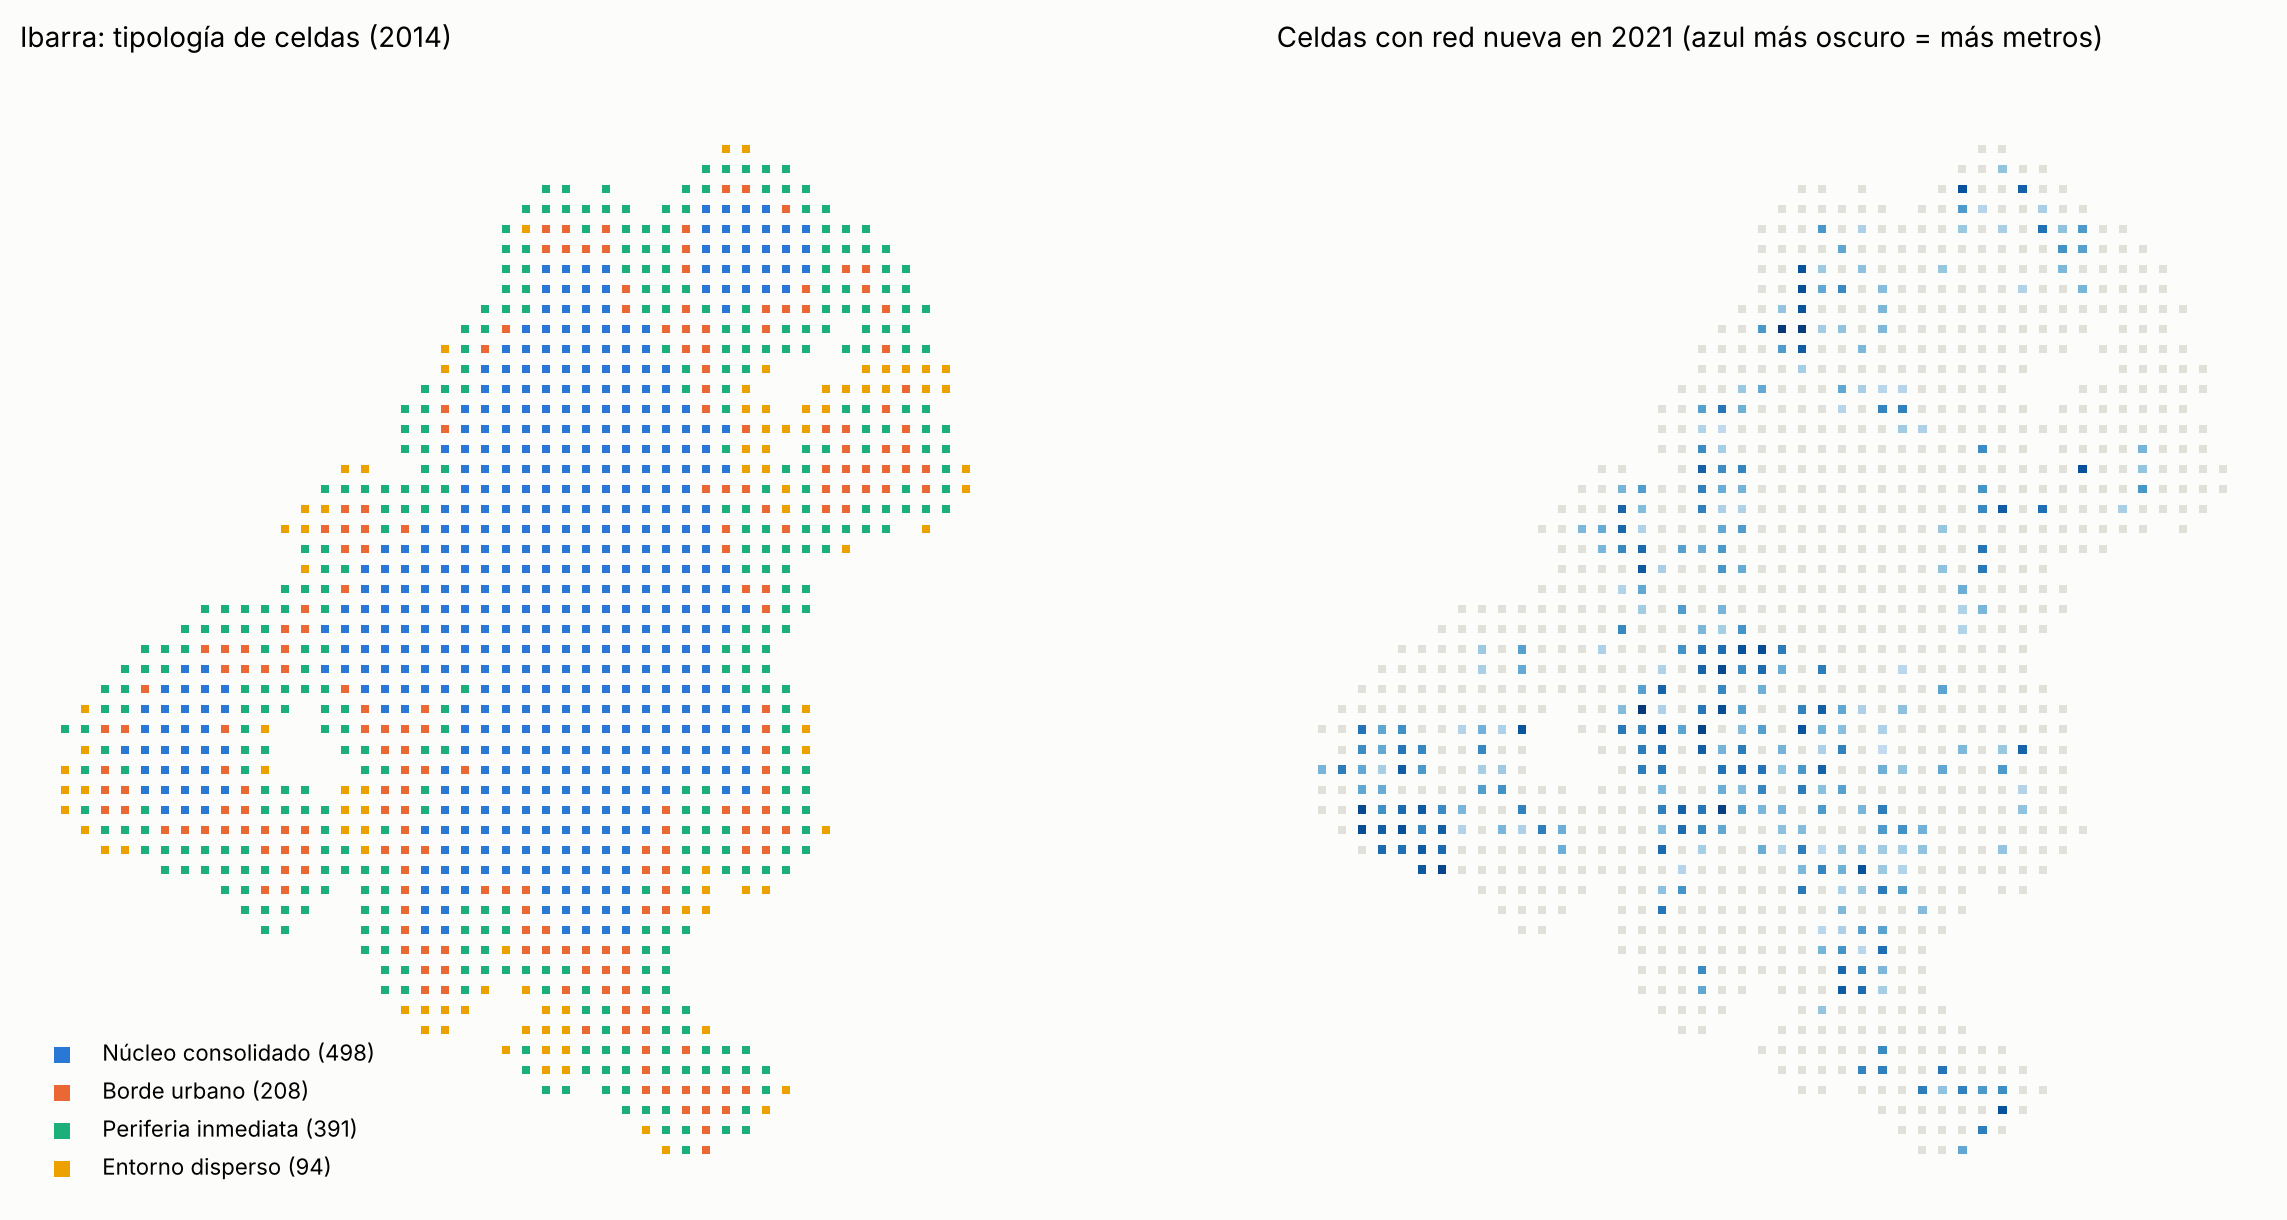

In [7]:
# Mapa de la tipología y de la red nueva observada (primera ciudad)
c0 = celdas[celdas.ciudad == CIUDADES[0]]
zona = c0[c0.dist_nucleo <= 3000]                      # acercamiento al área urbana
fig, axs = plt.subplots(1, 2, figsize=(13, 6.2))
for t, nombre in enumerate(nombres):
    s = zona[zona.tipo == t]
    axs[0].scatter(s.x, s.y, s=9, marker="s", color=COLOR_TIPO[t % len(COLOR_TIPO)], label=f"{nombre} ({len(s)})", linewidths=0)
axs[0].legend(loc="lower left", fontsize=8, frameon=False, markerscale=2)
axs[0].set_title(f"{CIUDADES[0].title()}: tipología de celdas ({ANIOS['antigua']})")
axs[1].scatter(zona.x, zona.y, s=9, marker="s", color="#e1e0d9", linewidths=0)
s = zona[zona.crece == 1]
axs[1].scatter(s.x, s.y, s=9, marker="s", c=np.log10(s.m_nuevos), cmap="Blues", vmin=1.2, vmax=3.2, linewidths=0)
axs[1].set_title(f"Celdas con red nueva en {ANIOS['actual']} (azul más oscuro = más metros)")
for ax in axs: ax.set_aspect("equal"); ax.set_axis_off()
plt.tight_layout(); plt.show()

### 5. Modelos
**Objetivo:** `crece`. **Predictores:** las ocho variables de 2014 (`urbano.VARIABLES`); ninguna usa información de 2021.

**Validación cruzada espacial.** Las celdas se agrupan en bloques de 2 km y cada bloque entra completo en un solo pliegue. Así el modelo se evalúa sobre zonas que no vio, que es lo que ocurre al aplicarlo a otra ciudad.

Se comparan cinco formas de usar la información, tres de ellas con los clusters:

| Modelo | Uso de los clusters |
|---|---|
| Referencia | ninguno: predice la proporción de celdas con red nueva |
| Solo tipología | la probabilidad es la proporción observada en el tipo de la celda |
| Global | ninguno: un modelo para todas las celdas |
| Global + tipo | el tipo entra como un predictor más |
| Un modelo por tipo | un modelo ajustado dentro de cada cluster |

**Métricas.** AUC (0,5 = azar), precisión media AP (su valor de azar es la proporción de positivos) y Brier (error cuadrático de la probabilidad; menor es mejor).

In [8]:
X, y = celdas[u.VARIABLES], celdas.crece
bloque = (celdas.ciudad + "_" + np.floor(celdas.x / TAM_BLOQUE).astype(int).astype(str)
          + "_" + np.floor(celdas.y / TAM_BLOQUE).astype(int).astype(str))
pliegues = list(GroupKFold(N_PLIEGUES).split(X, y, bloque))
tipo = celdas.tipo.to_numpy()

def logistica(): return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
def bosque():    return RandomForestClassifier(N_ARBOLES, min_samples_leaf=MIN_HOJA, random_state=SEMILLA, n_jobs=-1)

def p_referencia(tr, te): return np.full(len(te), y.iloc[tr].mean())
def p_solo_tipo(tr, te):
    tasa = y.iloc[tr].groupby(tipo[tr]).mean()
    return pd.Series(tipo[te]).map(tasa).fillna(y.iloc[tr].mean()).to_numpy()
def p_global(fabrica, con_tipo=False):
    def f(tr, te):
        A = X.assign(tipo=tipo) if con_tipo else X
        return fabrica().fit(A.iloc[tr], y.iloc[tr]).predict_proba(A.iloc[te])[:, 1]
    return f
def p_por_tipo(fabrica):
    def f(tr, te):
        p = np.zeros(len(te))
        for t in range(N_TIPOS):
            a, b = tr[tipo[tr] == t], te[tipo[te] == t]
            if len(b) == 0: continue
            # un tipo con una sola clase en entrenamiento no se puede ajustar: usa su proporción
            p[tipo[te] == t] = (fabrica().fit(X.iloc[a], y.iloc[a]).predict_proba(X.iloc[b])[:, 1]
                                if y.iloc[a].nunique() == 2 else y.iloc[a].mean())
        return p
    return f

candidatos = {
    "Referencia (proporción)": p_referencia,
    "Solo tipología": p_solo_tipo,
    "Logística global": p_global(logistica),
    "Random forest global": p_global(bosque),
    "Random forest global + tipo": p_global(bosque, con_tipo=True),
    "Logística por tipo": p_por_tipo(logistica),
    "Random forest por tipo": p_por_tipo(bosque),
}
fuera, filas = {}, []          # predicciones fuera de pliegue de cada candidato
for nombre, f in candidatos.items():
    p = np.zeros(len(y))
    for tr, te in pliegues: p[te] = f(tr, te)
    fuera[nombre] = p
    auc_p = [roc_auc_score(y.iloc[te], p[te]) for _, te in pliegues]
    filas.append({"modelo": nombre, "AUC": np.mean(auc_p), "AUC desv.": np.std(auc_p),
                  "AP": average_precision_score(y, p), "Brier": brier_score_loss(y, p)})
metricas = pd.DataFrame(filas).set_index("modelo")
print(f"Celdas: {len(y):,} | con red nueva: {y.mean():.1%} | bloques: {bloque.nunique()} | pliegues: {N_PLIEGUES}")
metricas.round(3)

Celdas: 1,564 | con red nueva: 23.0% | bloques: 61 | pliegues: 5


,AUC,AUC desv.,AP,Brier
modelo,,,,
Referencia (proporción),0.500,0.000,0.201,0.179
Solo tipología,0.695,0.030,0.310,0.159
Logística global,0.774,0.031,0.435,0.150
Random forest global,0.782,0.043,0.479,0.146
Random forest global + tipo,0.781,0.044,0.473,0.147
Logística por tipo,0.759,0.031,0.414,0.155
Random forest por tipo,0.777,0.047,0.473,0.147


Random forest global | AUC con partición aleatoria: 0.801 | AUC con partición espacial: 0.780


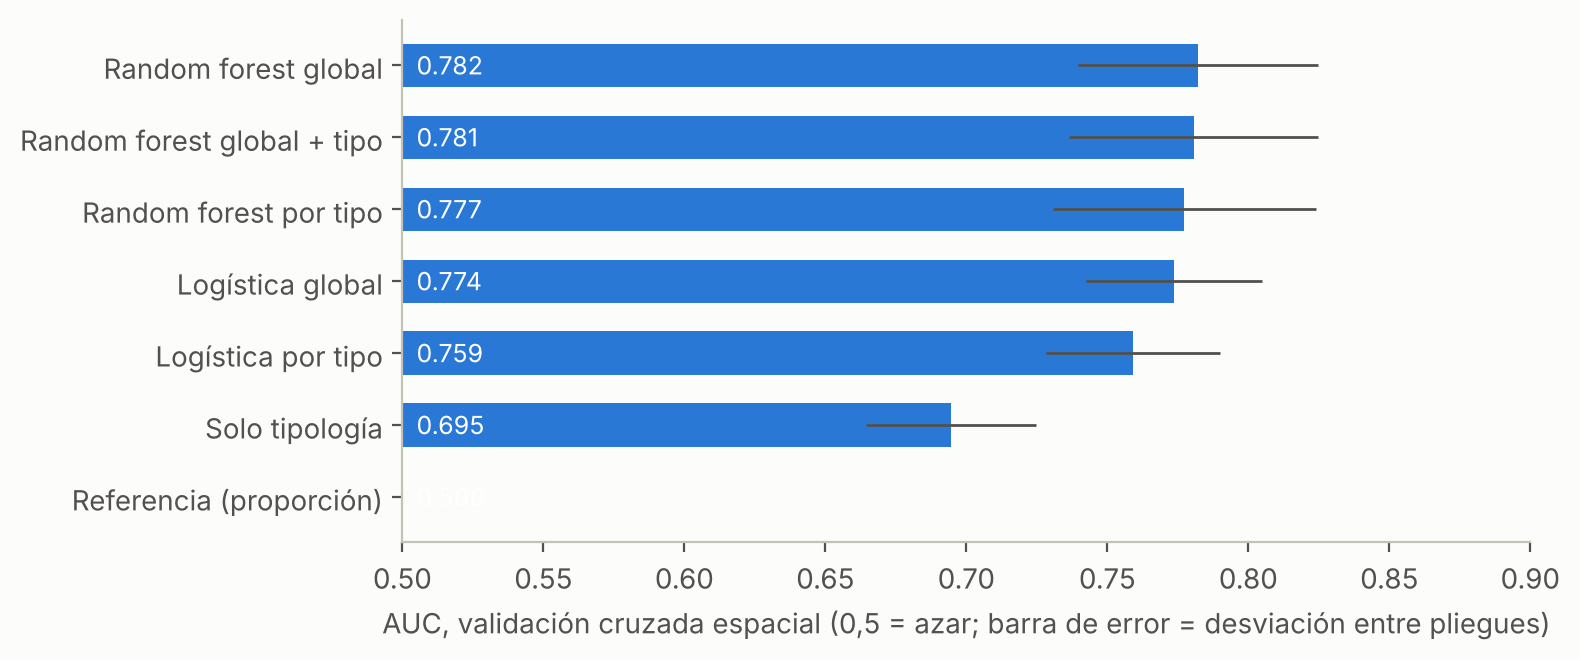

In [9]:
# Cuánto infla las métricas una partición aleatoria (se muestra solo como contraste; no se usa)
p_al = np.zeros(len(y))
for tr, te in StratifiedKFold(N_PLIEGUES, shuffle=True, random_state=SEMILLA).split(X, y):
    p_al[te] = bosque().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
print(f"Random forest global | AUC con partición aleatoria: {roc_auc_score(y, p_al):.3f} | "
      f"AUC con partición espacial: {roc_auc_score(y, fuera['Random forest global']):.3f}")

m = metricas.sort_values("AUC")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(m.index, m.AUC, xerr=m["AUC desv."], color=AZUL, height=0.6, error_kw={"ecolor": TINTA, "linewidth": 1})
for i, v in enumerate(m.AUC): ax.text(0.505, i, f"{v:.3f}", va="center", color="white", fontsize=9)
ax.set(xlim=(0.5, 0.9), xlabel="AUC, validación cruzada espacial (0,5 = azar; barra de error = desviación entre pliegues)")
plt.tight_layout(); plt.show()

**Lectura.** *(Los valores citados corresponden a la ejecución con Ibarra.)*

- Todos los modelos superan a la referencia; en el notebook anterior ninguno lo hacía.
- **La tipología por sí sola ya predice**, pero menos que un modelo con las variables continuas.
- **Añadir el tipo como predictor no aporta**: el tipo se construyó con las mismas variables, así que no trae información nueva.
- **Un modelo por tipo no mejora al global**: queda igual o algo por debajo, con diferencias menores que la variación entre pliegues. Cada modelo ve solo una fracción de las celdas y el corte entre tipos es arbitrario en un gradiente continuo, así que se paga en datos sin ganar en ajuste.

Conclusión de diseño: los clusters son útiles para **describir y comunicar** (qué tejido es y con qué frecuencia crece), y el modelo **global** es el que predice. Se despliegan los dos con ese reparto de papeles.

### 6. Modelo final
Random forest global. Las métricas que siguen usan sus predicciones **fuera de pliegue**, es decir, sobre celdas que el modelo no vio al ajustarse.

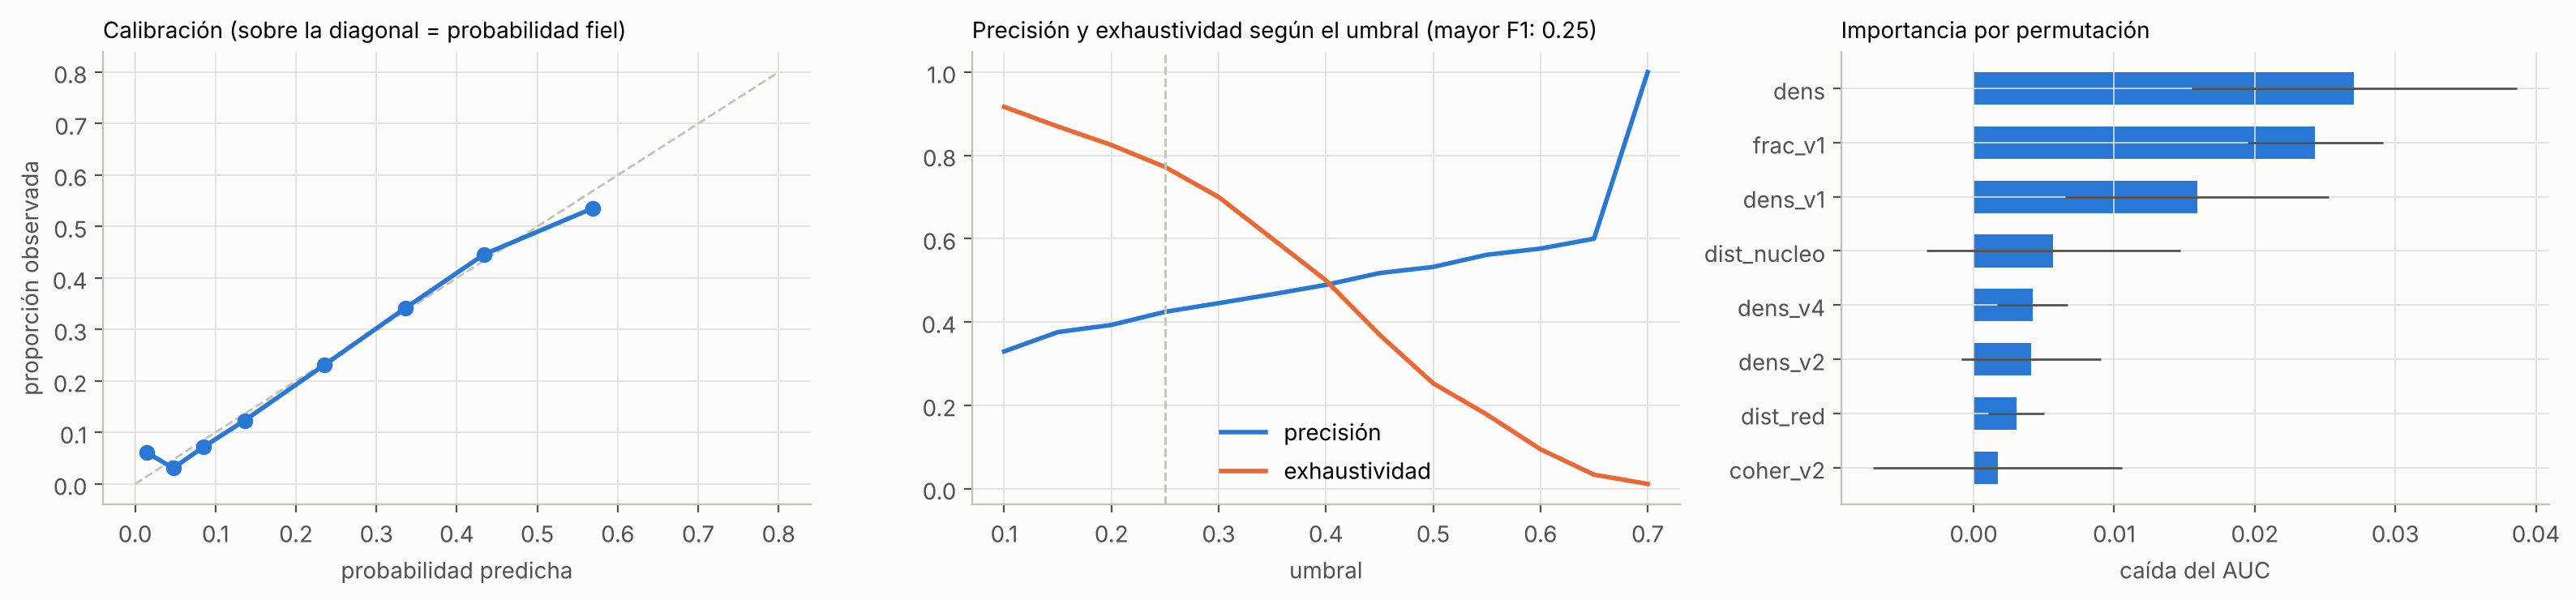

,celdas señaladas,precisión,exhaustividad,F1
umbral,,,,
0.2,756,0.393,0.825,0.532
0.3,566,0.445,0.700,0.544
0.4,368,0.489,0.500,0.495
0.5,171,0.532,0.253,0.343


In [10]:
ELEGIDO = "Random forest global"
p = fuera[ELEGIDO]

# Umbral: tabla de precisión y exhaustividad; por defecto, el de mayor F1
umbrales = pd.DataFrame([{"umbral": t, "celdas señaladas": int((p >= t).sum()),
                          "precisión": precision_score(y, p >= t, zero_division=0),
                          "exhaustividad": recall_score(y, p >= t)} for t in np.arange(0.1, 0.75, 0.05).round(2)]).set_index("umbral")
umbrales["F1"] = 2 * umbrales.precisión * umbrales.exhaustividad / (umbrales.precisión + umbrales.exhaustividad)
UMBRAL = float(umbrales.F1.idxmax())

# Importancia por permutación en cada pliegue de prueba (caída del AUC al desordenar la variable)
imp = []
for tr, te in pliegues:
    mf = bosque().fit(X.iloc[tr], y.iloc[tr])
    imp.append(permutation_importance(mf, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=10,
                                      random_state=SEMILLA, n_jobs=-1).importances_mean)
importancia = pd.DataFrame({"caída_AUC": np.mean(imp, axis=0), "desv": np.std(imp, axis=0)}, index=u.VARIABLES).sort_values("caída_AUC")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
obs, pred = calibration_curve(y, p, n_bins=8, strategy="quantile")
axs[0].plot([0, 0.8], [0, 0.8], color=GRIS, linewidth=1, linestyle="--")
axs[0].plot(pred, obs, color=AZUL, linewidth=2, marker="o", markersize=6)
axs[0].set(title="Calibración (sobre la diagonal = probabilidad fiel)", xlabel="probabilidad predicha", ylabel="proporción observada")
axs[1].plot(umbrales.index, umbrales.precisión, color=COLOR_TIPO[0], linewidth=2, label="precisión")
axs[1].plot(umbrales.index, umbrales.exhaustividad, color=COLOR_TIPO[1], linewidth=2, label="exhaustividad")
axs[1].axvline(UMBRAL, color=GRIS, linewidth=1, linestyle="--")
axs[1].set(title=f"Precisión y exhaustividad según el umbral (mayor F1: {UMBRAL:.2f})", xlabel="umbral"); axs[1].legend(frameon=False)
axs[2].barh(importancia.index, importancia.caída_AUC, xerr=importancia.desv, color=AZUL, height=0.6, error_kw={"ecolor": TINTA, "linewidth": 1})
axs[2].set(title="Importancia por permutación", xlabel="caída del AUC")
for ax in axs: ax.grid(color="#e1e0d9", linewidth=0.6)
plt.tight_layout(); plt.show()
umbrales.loc[[0.2, 0.3, 0.4, 0.5]].round(3)

### 7. Exportación
El modelo final se ajusta con **todas** las celdas y se guarda junto con la tipología en un solo archivo. El paquete incluye las versiones de las librerías: `joblib` solo garantiza la lectura con la misma versión de scikit-learn, por eso `requirements.txt` la fija.

In [11]:
modelo = bosque().fit(X, y)
paquete = {
    "modelo": modelo, "tipologia": tipologia, "orden": orden.tolist(), "nombres_tipos": nombres,
    "variables": u.VARIABLES, "umbral": UMBRAL, "ciudades": CIUDADES, "anios": ANIOS,
    "perfil": perfil.round(3), "metricas": metricas.round(4), "umbrales": umbrales.round(4),
    "importancia": importancia.round(4), "elegido": ELEGIDO,
    "n_celdas": int(len(y)), "prevalencia": float(y.mean()),
    "parametros": {k: getattr(u, k) for k in ["TAM_CELDA", "RADIO_UNIVERSO", "DIST_NUEVA", "MIN_NUEVA_M", "DENS_NUCLEO"]},
    "medianas_tipo": celdas.groupby("tipo")[u.VARIABLES].median().round(3),
    "rangos": X.quantile([0, 0.5, 0.99]).round(3).T.set_axis(["min", "mediana", "p99"], axis=1),
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__},
}
RUTA_PAQUETE.parent.mkdir(exist_ok=True)
joblib.dump(paquete, RUTA_PAQUETE, compress=3)
print(f"{RUTA_PAQUETE}: {RUTA_PAQUETE.stat().st_size / 1e6:.2f} MB | versiones: {paquete['versiones']}")

# Comprobación: el paquete leído del disco reproduce las predicciones
leido = joblib.load(RUTA_PAQUETE)
assert np.allclose(u.predecir(celdas, leido).prob, modelo.predict_proba(X)[:, 1])
print("Paquete verificado. Siguiente paso: 02_despliegue.ipynb")

modelo/paquete.joblib: 0.81 MB | versiones: {'python': '3.13.18', 'scikit-learn': '1.9.1', 'numpy': '2.5.3'}
Paquete verificado. Siguiente paso: 02_despliegue.ipynb


## 8. Conclusiones

1. **El cambio de unidad es lo que da capacidad predictiva.** Con las mismas dos capas, el modelo por área no superaba a la media; el modelo por celda separa las celdas que reciben red nueva de las que no, en zonas que no vio. La capacidad es **moderada**: con el umbral de mayor F1, unas cuatro de cada diez celdas señaladas reciben red nueva (frente a una de cada cuatro al azar) y se detectan tres de cada cuatro.
2. **Qué predice.** La red nueva aparece junto a la red existente: pesan la densidad de la celda y de su vecindad y la distancia a la red. Es un modelo de **contigüidad**: dice *dónde* es más probable, a partir de la forma de la red, y no *por qué*.
3. **Clusters.** La tipología ordena las celdas del núcleo a la periferia y sus tasas de crecimiento son distintas, pero los datos son un gradiente y no grupos separados (silueta máxima en k = 2). Modelar por cluster no mejora al modelo global.
4. **Límites.**
   - Entrenado con **una sola ciudad**. La validación espacial evalúa zonas no vistas de esa ciudad; aplicarlo a otra es una extrapolación que aún no está medida.
   - La red "nueva" incluye **diferencias de levantamiento** entre las dos bases (la 2021 es más detallada), sobre todo dentro del núcleo consolidado, donde parte de lo nuevo son pasajes ya existentes.
   - Las celdas a más de 500 m de la red 2014 quedan fuera: el modelo no puede anticipar urbanizaciones aisladas.
   - No hay variables externas (pendiente, población, uso de suelo, áreas protegidas).

**Trabajo futuro.** Entrenar con varias ciudades y validar dejando ciudades completas fuera (`GroupKFold` por ciudad); añadir pendiente y población censal; excluir tipos de eje no vehiculares para reducir el efecto del levantamiento.